In [1]:
import pandas as pd


In [2]:
df = pd.read_csv('data/DS6021-Fall26-Anonymized.csv')
df

,Timestamp,What was your undergraduate major?,What type of phone do you have?,How many years ago did you receive your undergraduate degree?,How many hours do you sleep in a typical night?,Rate your proficiency with git/github,Rate your proficiency with Python,Have you ever used SQL?,What is your favorite sport to watch on tv?,What is your ideal outdoor temperature (in Fahrenheit)?,How many US states have you visited?,What is your favorite season?
0,8/25/2026 8:20:43,Psychology,iPhone,4-6 years,8,3,2,Yes,F1 motorsport,70,8,Fall
1,8/25/2026 9:35:51,Statistics,iPhone,1-3 years,8,3,4,Yes,NaN,70,16,Fall
2,8/25/2026 13:43:23,Economics-Business and Applied Mathematics,iPhone,< 1 year,8,3,3,No,Baseball,70,27,Fall
3,8/25/2026 15:11:38,Data Science (concentration in Computer Science),iPhone,< 1 year,8,3,4,Yes,Football (go Bears!),73,9,Fall
4,8/25/2026 15:26:11,Math and Physics,iPhone,1-3 years,8,2,4,Yes,Figure Skating,73,26,Fall
...,...,...,...,...,...,...,...,...,...,...,...,...
81,8/26/2026 11:42:57,Bioinformatics and Biology,iPhone,< 1 year,5-7,2,3,No,Football,40 degrees,16,Winter
82,8/26/2026 11:44:34,Computer Science,iPhone,< 1 year,4 - 6,3,3,Yes,Soccer,75,1,Summer
83,8/26/2026 11:48:23,IT-Concentration in Data Science,iPhone,1-3 years,6.5,3,3,Yes,Soccer and Fustal,68,5,Spring
84,8/26/2026 11:52:24,Data Science,iPhone,< 1 year,7,4,4,No,Football,63,"If I had to guess, 23",Fall


In [3]:
print("Dataset shape:", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (86, 12)

Data types:
Timestamp                                                        object
What was your undergraduate major?                               object
What type of phone do you have?                                  object
How many years ago did you receive your undergraduate degree?    object
How many hours do you sleep in a typical night?                  object
Rate your proficiency with git/github                             int64
Rate your proficiency with Python                                 int64
Have you ever used SQL?                                          object
What is your favorite sport to watch on tv?                      object
What is your ideal outdoor temperature (in Fahrenheit)?          object
How many US states have you visited?                             object
What is your favorite season?                                    object
dtype: object

Missing values:
Timestamp                                                        0
W

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

col_mapping = {
    'Timestamp': 'timestamp',
    'What was your undergraduate major?': 'major',
    'What type of phone do you have?': 'phone_type',
    'How many years ago did you receive your undergraduate degree?': 'years_since_degree',
    'How many hours do you sleep in a typical night?': 'sleep_hours',
    'Rate your proficiency with git/github': 'git_prof',
    'Rate your proficiency with Python': 'python_prof',
    'Have you ever used SQL?': 'used_sql',
    'What is your favorite sport to watch on tv?': 'fav_sport',
    'What is your ideal outdoor temperature (in Fahrenheit)?': 'ideal_temp',
    'How many US states have you visited?': 'states_visited',
    'What is your favorite season?': 'fav_season'
}
df.rename(columns=col_mapping, inplace=True)

df['timestamp'] = pd.to_datetime(df['timestamp'])

def clean_sleep(val):
    if pd.isna(val):
        return np.nan
    val_str = str(val).split('-')[0].strip()
    return pd.to_numeric(val_str, errors='coerce')

df['sleep_hours'] = df['sleep_hours'].apply(clean_sleep)

df['ideal_temp'] = df['ideal_temp'].astype(str).str.extract(r'(\d+)').astype(float)
df['states_visited'] = df['states_visited'].astype(str).str.extract(r'(\d+)').astype(float)

categorical_cols = ['phone_type', 'years_since_degree', 'used_sql', 'fav_season']
for col in categorical_cols:
    df[col] = df[col].astype('category')

In [5]:
df

,timestamp,major,phone_type,years_since_degree,sleep_hours,git_prof,python_prof,used_sql,fav_sport,ideal_temp,states_visited,fav_season
0,2026-08-25 08:20:43,Psychology,iPhone,4-6 years,8.0,3,2,Yes,F1 motorsport,70.0,8.0,Fall
1,2026-08-25 09:35:51,Statistics,iPhone,1-3 years,8.0,3,4,Yes,NaN,70.0,16.0,Fall
2,2026-08-25 13:43:23,Economics-Business and Applied Mathematics,iPhone,< 1 year,8.0,3,3,No,Baseball,70.0,27.0,Fall
3,2026-08-25 15:11:38,Data Science (concentration in Computer Science),iPhone,< 1 year,8.0,3,4,Yes,Football (go Bears!),73.0,9.0,Fall
4,2026-08-25 15:26:11,Math and Physics,iPhone,1-3 years,8.0,2,4,Yes,Figure Skating,73.0,26.0,Fall
...,...,...,...,...,...,...,...,...,...,...,...,...
81,2026-08-26 11:42:57,Bioinformatics and Biology,iPhone,< 1 year,5.0,2,3,No,Football,40.0,16.0,Winter
82,2026-08-26 11:44:34,Computer Science,iPhone,< 1 year,4.0,3,3,Yes,Soccer,75.0,1.0,Summer
83,2026-08-26 11:48:23,IT-Concentration in Data Science,iPhone,1-3 years,6.5,3,3,Yes,Soccer and Fustal,68.0,5.0,Spring
84,2026-08-26 11:52:24,Data Science,iPhone,< 1 year,7.0,4,4,No,Football,63.0,23.0,Fall


Univariate Exploration


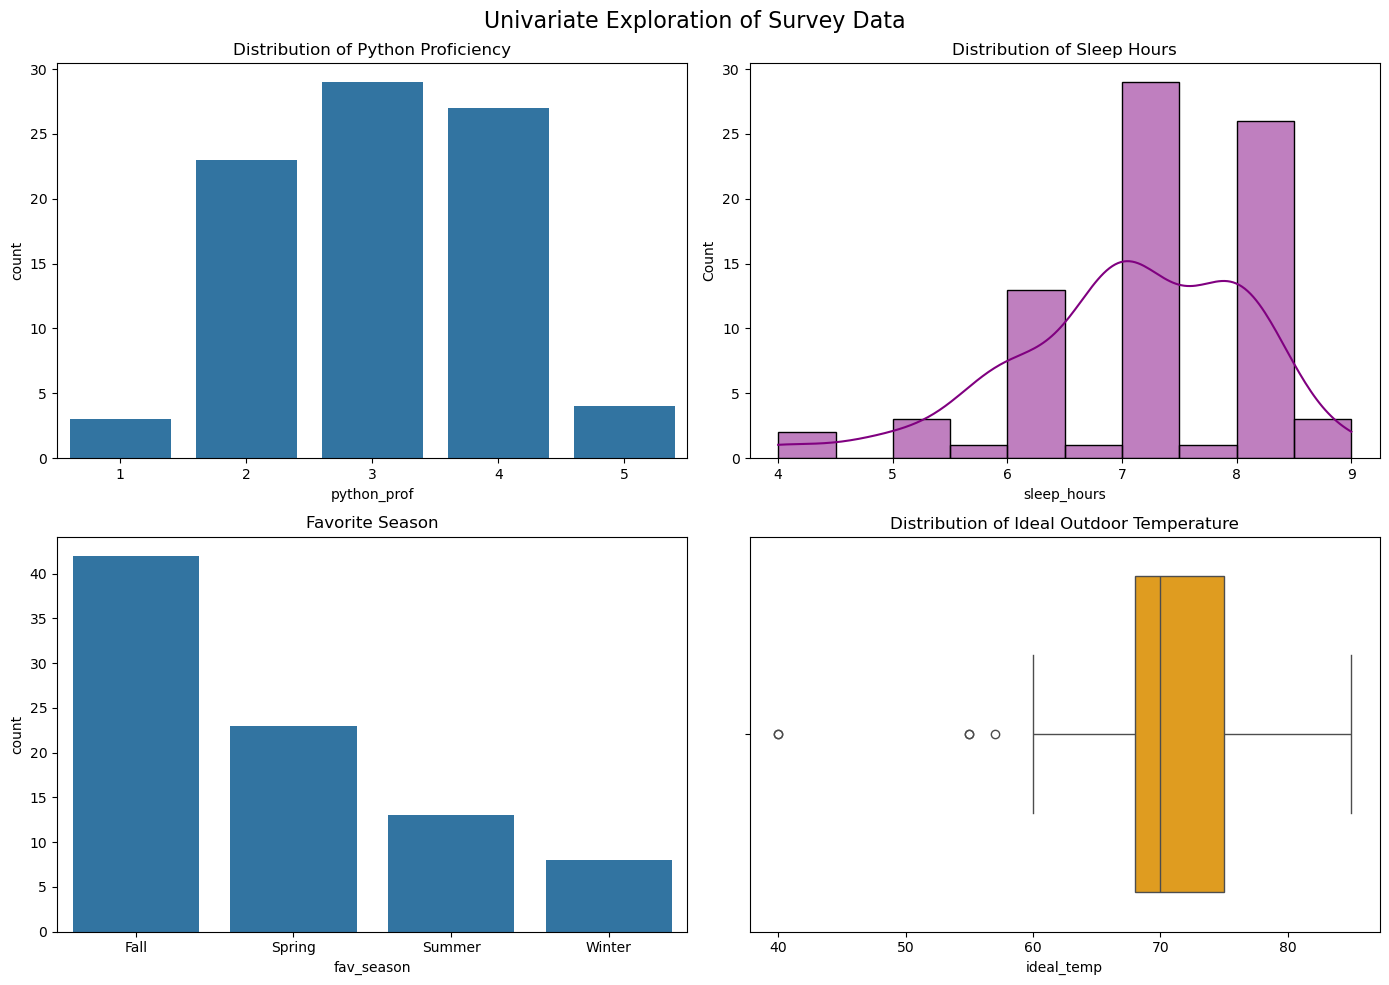

Bivariate Exploration


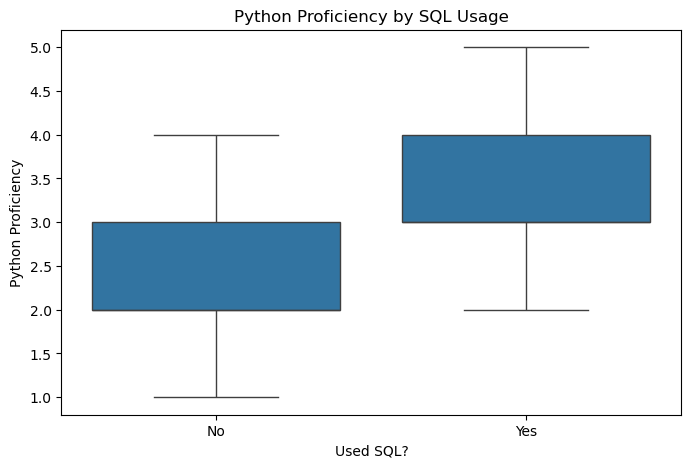

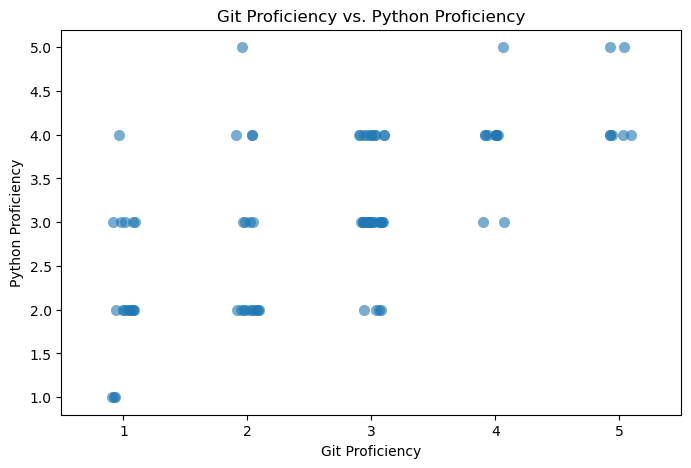

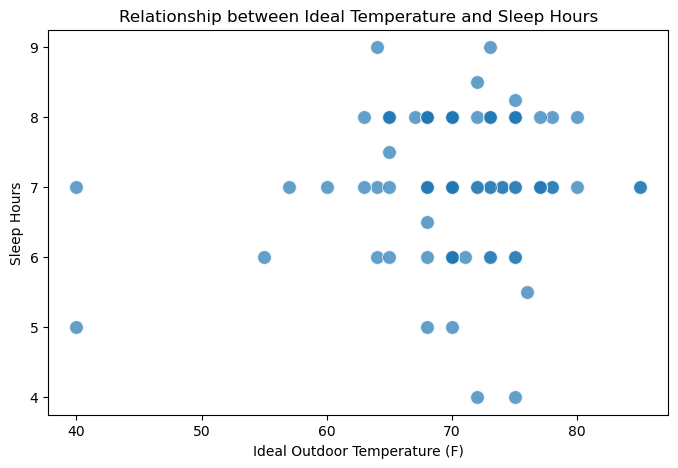

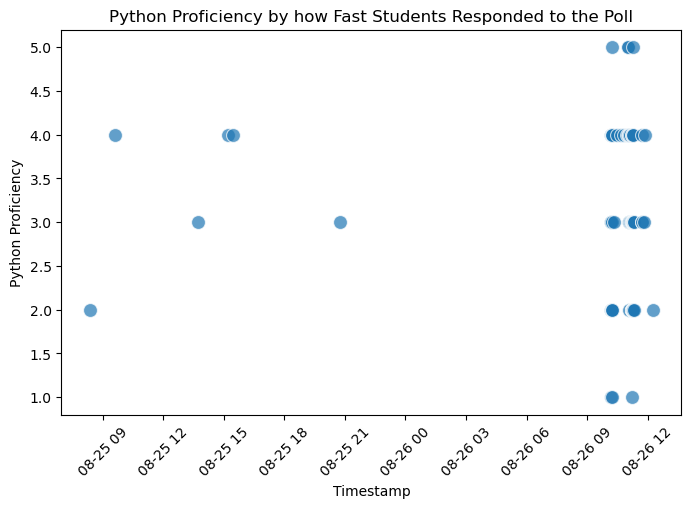

In [6]:
print("Univariate Exploration")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Univariate Exploration of Survey Data', fontsize=16)

# 1 Python Proficiency
sns.countplot(data=df, x='python_prof', ax=axes[0, 0])
axes[0, 0].set_title('Distribution of Python Proficiency')

# 2 Sleep
sns.histplot(data=df, x='sleep_hours', bins=10, kde=True, ax=axes[0, 1], color='purple')
axes[0, 1].set_title('Distribution of Sleep Hours')

# 3 Season
sns.countplot(data=df, x='fav_season', ax=axes[1, 0])
axes[1, 0].set_title('Favorite Season')

# 4 Temp
sns.boxplot(data=df, x='ideal_temp', ax=axes[1, 1], color='orange')
axes[1, 1].set_title('Distribution of Ideal Outdoor Temperature')

plt.tight_layout()
plt.show()

print("Bivariate Exploration")

# 1 SQL vs. Python
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='used_sql', y='python_prof')
plt.title('Python Proficiency by SQL Usage')
plt.xlabel('Used SQL?')
plt.ylabel('Python Proficiency')
plt.show()

# 2 Git vs. Python
plt.figure(figsize=(8, 5))
sns.stripplot(data=df, x='git_prof', y='python_prof', jitter=True, alpha=0.6, size=8)
plt.title('Git Proficiency vs. Python Proficiency')
plt.xlabel('Git Proficiency')
plt.ylabel('Python Proficiency')
plt.show()

# 3 Sleep vs Temp
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='ideal_temp', y='sleep_hours', alpha=0.7, s=100)
plt.title('Relationship between Ideal Temperature and Sleep Hours')
plt.xlabel('Ideal Outdoor Temperature (F)')
plt.ylabel('Sleep Hours')
plt.show()

# 4 Timestamp vs Python
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x='timestamp', y='python_prof', alpha = 0.7, s=100)
plt.title('Python Proficiency by how Fast Students Responded to the Poll')
plt.xlabel('Timestamp')
plt.ylabel('Python Proficiency')
plt.xticks(rotation=45)
plt.show()

# Reflections

### Is there anything about the dataset that surprised you?
- How finicky peoples' answers can be and how difficult that makes cleaning the data. For example the sleep part, many people gave ranges and/or an explantion as to why they sleep however much they do. 
### For some of the survey response questions, there are multiple ways that one could clean the data. For two different examples where you had a choice to make, please discuss the alternatives that you considered and why you made the choice that you ultimately did.
- Going back to the sleep responses, for those that gave a range it would make sense to average the two numbers but I figured, hey, we're all in grad school now so we're likely getting the minimum number of hours. So if students responded with a range, I split the numbers at the dash and took the first one that they listed.
- For the temperatures, students entered things like '70 degrees' which can't be easily casted to an integer. I could've used pd.to_numeric() and coerced the errors but it would create a bunch of NaN values. Instead, I decided to turn it into a string and then pull any digits from the string and make them a float, that way it stripped all of the text aroudn the actual answer. 
### In the first part of this assignment, I asked you to use Python as opposed to cleaning the data in Excel or Google Sheets. In a business context, what is a potential negative outcome that could occur if you did this in Excel or Google sheets?
- If you clean the data within excel or sheets, you're altering the original data which likely doesn't have a backup. When working in python, you can always reload the dataset and keep the original data. 